In [1]:
import copy
import types
from ipywidgets import interact, widgets
import os
workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))

import sys
sys.path.append(workspace_path)

import lib.constants as constants
from lib.utils_real import *
from lib.optimization import *
from config.real_objects import get_config, available_objects

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    torch.set_default_tensor_type(torch.cuda.FloatTensor)
else:
    device = torch.device("cpu")

# Macros

## Object selection

`OBJECT` picks the recording to reconstruct. `BASELINE = True` runs the
comparison setting instead: shape from heat conduction alone, with the shading
stage switched off. Every per-object value lives in `config/real_objects.py`.

In [3]:
OBJECT = "paintedbear"   # see available_objects()
BASELINE = False         # True: heat conduction only, no shading constraint

cfg = get_config(OBJECT, baseline=BASELINE)
print("objects         :", available_objects())
print("with comparison :", available_objects(baseline=True))
print(f"\n{cfg.exp_name}: {len(cfg.videos)} view(s), "
      f"{cfg.num_ST_loops} shape-temperature loop(s), use_shading={cfg.use_shading}")

objects         : ['bear', 'bunny', 'droplet', 'heart', 'paintedbear', 'soda_can', 'sphere']
with comparison : ['bear', 'heart', 'paintedbear', 'soda_can', 'sphere']

paintedbear: 1 view(s), 2 shape-temperature loop(s), use_shading=True


In [4]:
# Common and per-object values both come from config/real_objects.py
params_dict = {**cfg.params, "device": device}

params = types.SimpleNamespace(**params_dict)
constants.set_focus_distance(params.obj_dist * 1000.0)

FOCUS_DISTANCE set:  444.5


# Load Video

In [5]:
video_filenames = cfg.videos

views_azim_angles = [0]
views_elev_angles = [0]

# Light direction
ps_gt = params.light_directions[0][0] / params.light_directions[0][2]
qs_gt = params.light_directions[0][1] / params.light_directions[0][2]
params.num_files = len(video_filenames)

# Material constants
params.K = constants.TDiff[params.obj_material]
params.RHO = constants.Density[params.obj_material]
params.C = constants.SpecificHeat[params.obj_material]
params.ABS = constants.Absorptivity[params.obj_material]


## Read Frames

In [6]:
frame_recording = []
for video_filename in tqdm(video_filenames):
    if params.optimize_MinvL:
        data = np.load(os.path.join(workspace_path, 'DATA', 'obj_study_raw', video_filename), allow_pickle=True)
        recording = data["frame_recording"]
        if len(recording.shape) == 3:
            recording = recording[np.newaxis]
        del data
        frame_recording.append(recording[0, params.NUM_BG_FRAMES+10::params.NUM_FRAME_DELTA])
        print(frame_recording[-1].shape)
        del recording

min_frames = min([x.shape[0] for x in frame_recording])
frame_recording = [x[:min_frames] for x in frame_recording]
frame_recording = np.array(frame_recording)


100%|██████████| 1/1 [00:00<00:00, 33.18it/s]

(189, 510, 640)


# Load Mask

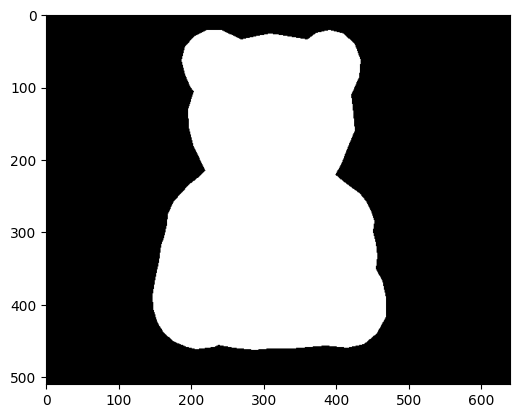

In [7]:
frame_mask = []
mask_filename = video_filenames[0].split('.')[0] + '_mask.png'
mask_filepath = os.path.join(workspace_path, 'DATA', 'obj_study_proc', mask_filename)
png_file = True

# Check if mask file exists
if not os.path.exists(mask_filepath):
    mask_filename = video_filenames[0].split('.')[0] + '_mask.pkl'
    mask_filepath = os.path.join(workspace_path, 'DATA', 'obj_study_proc', mask_filename)
    png_file = False
try:
    if not png_file:
        print('Loading mask from {}'.format(mask_filepath))
        with open(mask_filepath, 'rb') as f:
            mask_dict = pkl.load(f)
            frame_mask.append(mask_dict['mask'])
            print('Loaded mask with mean {} and stdrange = {}'.format(mask_dict['mean'], mask_dict['stdrange']))
            del mask_dict
    else:
        mask = cv2.imread(mask_filepath, 0)/255.0
        mask = mask.astype(int)
        frame_mask.append(mask)
except Exception as e:
    print(e)

frame_mask = np.array(frame_mask)
combined_mask = np.any(frame_mask, axis=0)
plt.imshow(combined_mask, cmap='gray')
plt.show()
view_masks_forobj = np.stack(frame_mask, axis=0).astype(int)

# Preprocessing

## Counts to Temperature 

In [8]:
frames_temp = []
for k in range(len(frame_recording)):
    frames_temp_view = []
    for i in tqdm(range(frame_recording[k].shape[0])):
        out_temp = counts2temp(frame_recording[k][i].copy(), constants.CAMERA)
        frames_temp_view.append(out_temp)
    frames_temp_view = np.array(frames_temp_view)
    frames_temp.append(frames_temp_view)
frames_temp = np.array(frames_temp)

del frame_recording

100%|██████████| 189/189 [00:00<00:00, 551.31it/s]


## Vis Mask Over Frames

In [9]:
plt.close('all')
with plt.ioff():
    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)

vindx = np.where(view_masks_forobj[-1])
vmin = np.min(frames_temp[:, :, vindx[0], vindx[1]])
vmax = np.max(frames_temp[:, :, vindx[0], vindx[1]])
def update(val):
    ax.clear()
    ax.imshow(frames_temp[-1, int(val)]*view_masks_forobj[-1], cmap='hot', vmin=vmin, vmax=vmax)
    ax.set_title('Heat flow at t = {}, \n min-temp={:.2f} max-temp={:.2f}'.format(int(val), np.min(frames_temp[0, int(val), vindx[0], vindx[1]]), np.max(frames_temp[0, int(val), vindx[0], vindx[1]])))
    ax.axis('off')
    fig.canvas.draw()
    display(fig)

interact(update, val=widgets.IntSlider(min=0, max=frames_temp.shape[1]-1, step=1, value=0));

interactive(children=(IntSlider(value=0, description='val', max=188), Output()), _dom_classes=('widget-interac…

### Update Frames

In [10]:
FRAME_START = None
FRAME_END = None
if FRAME_START is not None or FRAME_END is not None:
    frames_temp = frames_temp[:, FRAME_START:FRAME_END]

### Render N views

In [11]:
with torch.no_grad():
    
    # Get a batch of viewing angles. 
    elev = torch.from_numpy(np.array(views_elev_angles)).to(dtype=torch.float, device=device)
    azim = torch.from_numpy(np.array(views_azim_angles)).to(dtype=torch.float, device=device)
    R, T = look_at_view_transform(dist=params.obj_dist, elev=elev, azim=azim, device=device, degrees=True)

# Optimization

## Laplacian-Opti Macros

In [12]:
Lopti_params_dict = {
    "num_iterations": 10000, # Number of optimization steps
    "learning_rate": 1e-2,  # Step size
    # Hyperparameter lambda of our method, used to compute the matrix (I + lambda_*L)
    "lambda_": 19,
    "lambda_pde": 1.0,
    "lambda_heat_reg": 1.0,
    "lr_step_size": 7000,
    "lr_gamma": 0.5,
    "min_theta": np.radians(0.0),
    "max_theta": np.radians(180.0),
    "min_edge_length": 0.0008,
}

Lopti_params = types.SimpleNamespace(**Lopti_params_dict)

## Shape-Opti Macros

In [13]:
Sopti_params_dict = dict(cfg.shape_opti)

Sopti_params = types.SimpleNamespace(**Sopti_params_dict)
print(Sopti_params_dict)

{'activate_laplacian_reg_after_step': 500, 'activate_normal_reg_after_step': 0, 'convection_coeff_opti': 0, 'heat_capacity_opti': 0, 'heat_source_opti': 0, 'heat_value_opti': 0, 'lambda_symmetric_verts': 10000.0, 'laplacian_reg': 0.0, 'learning_rate': 0.01, 'lr_gamma': 0.5, 'lr_step_size': 7000, 'mesh_edge_reg': 0.0, 'num_steps_for_symmetric_verts': 1000, 'reduce_diffusivity': 0, 'lambda_': 16, 'lambda_normal': 0.0005, 'lambda_pde': 150.0, 'normal_reg': 0.11, 'num_iterations': 500}


## Exp-name

In [14]:
filename = cfg.name
exp_name = cfg.exp_name
print(exp_name)

paintedbear


## Run Optimization

===== Shape-Temperature Optimization Loop 1 / 2 =====


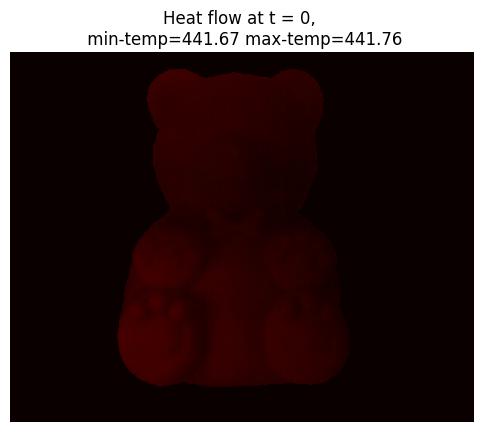

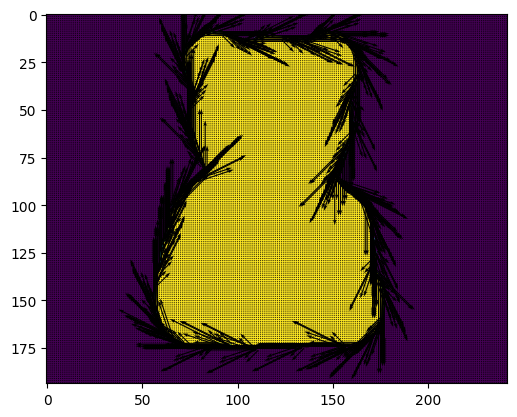

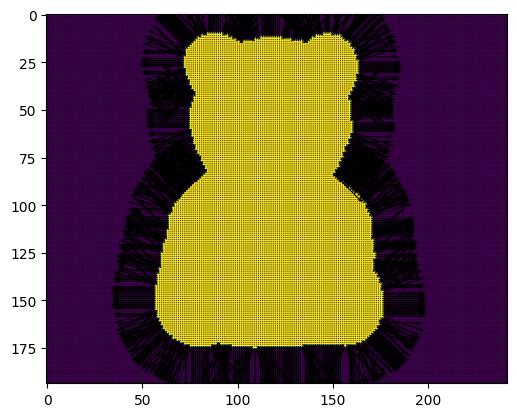

100%|██████████| 10000/10000 [01:01<00:00, 161.55it/s]

1


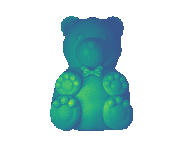

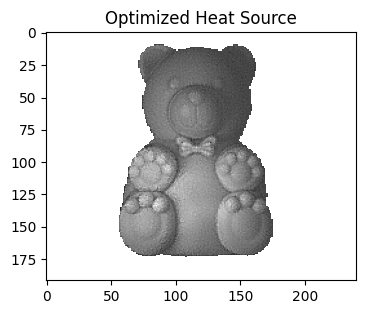

Heatcapacity: 0.003614296768233008
Convection coeff: 0.0008970011818389967


100%|██████████| 500/500 [00:09<00:00, 51.92it/s]


In [ ]:
writer = tb.SummaryWriter(log_dir=os.path.join(workspace_path, 'tb-logs', filename, exp_name))

verts_numpy = []
faces_numpy = []
num_ST_loops = cfg.num_ST_loops

depth_map = [None]
p_map = None
q_map = None

for outer_iter in range(num_ST_loops):
    print(f"===== Shape-Temperature Optimization Loop {outer_iter+1} / {num_ST_loops} =====")
    
    opti_wrapper = ShapeOptimizationWrapper(params=params, plot=True)
    opti_wrapper.prepare_renderers(R, T, params.max_img_size)

    # Resize view_masks_forobj to curr_img_size
    view_masks_resized = []
    for i in range(view_masks_forobj.shape[0]):
        view_masks_resized.append(cv2.resize(view_masks_forobj[i].astype(float),
                                             (params.max_img_size[1], params.max_img_size[0]),
                                             interpolation=cv2.INTER_NEAREST))

    view_masks_resized = (np.array(view_masks_resized) > 0).astype(int)
    if params.init_mesh_from_mask:
        view_masks_resized = np.any(view_masks_resized, axis=0).astype(int)[None,...]

    if depth_map[0] is not None:
        depth_map_resized = []
        for i in range(depth_map.shape[0]):
            depth_map_resized.append(cv2.resize(depth_map[i].astype(float),
                                                (params.max_img_size[1], params.max_img_size[0]),
                                                interpolation=cv2.INTER_CUBIC))
        depth_map = np.array(depth_map_resized)
        plt.subplot(1,2,1)
        plt.imshow(view_masks_resized[0])
        plt.subplot(1,2,2)
        plt.imshow(depth_map[0])
        plt.show()
    
    opti_wrapper.prepare_candidate_mesh(view_masks_resized[0].copy(), depth_map[0])
    opti_wrapper.map_heatvalues_tomesh(frames_temp)

    # ================== 1st Stage: Optimize Laplacian ==================
    if outer_iter == 0:
        opti_wrapper.initialize_Loptimaztion(Lopti_params)
        opti_wrapper.run_MinvLoptimization(writer,
                                                   filename=filename,
                                                   exp_name=exp_name)

        # Save optimization results
        optimization_results = opti_wrapper.get_optimization_results()
        opti_filename = f"opti_results{params.max_img_size[0]}x{params.max_img_size[1]}-Delta{params.NUM_FRAME_DELTA}.pkl"
        opti_path = os.path.join(workspace_path, 'DATA', 'obj_study_proc',  opti_filename)
        with open(opti_path, 'wb') as f:
            pkl.dump(optimization_results, f)
    else:
        opti_filename =f"opti_results{params.max_img_size[0]}x{params.max_img_size[1]}-Delta{params.NUM_FRAME_DELTA}.pkl"
        opti_path = os.path.join(workspace_path, 'DATA', 'obj_study_proc',  opti_filename)
        with open(opti_path, 'rb') as f:
            optimization_results = pkl.load(f)
        opti_wrapper.set_optimization_results(optimization_results)
    
    # Visualize optimized heat source (and update shading image)
    if params.optim_laplacian and params.optim_heat_source:
        heat_source_img = opti_wrapper.get_heatsource_img()
        if outer_iter == 0:
            plt_plot_first_nimages(heat_source_img.copy(), heat_source_img.shape[0])
            shading_img = heat_source_img
            plt.figure(figsize=(4, 4))
            plt.title("Optimized Heat Source")
            plt.imshow(shading_img[0], cmap='gray')
            plt.show()

    print("Heatcapacity:", (opti_wrapper.heat_capacity_opti.item())**2)
    print("Convection coeff:", (opti_wrapper.convection_coeff_opti.item())**2)
    
    # ================== 2nd Stage: Shape optimization ==================
    opti_wrapper.initialize_Soptimaztion(copy.deepcopy(Sopti_params))
    verts_numpy, faces_numpy, _, L_full = opti_wrapper.run_Soptimization(writer,
                                                                              verts_numpy,
                                                                              faces_numpy=faces_numpy,
                                                                              filename=filename,
                                                                              exp_name=exp_name,
                                                                              p_map=p_map,
                                                                              q_map=q_map)

    # ================== 3rd Stage: Optimize per-pixel t ==================
    # Skipped for the comparison setting, which uses heat conduction only.
    if cfg.use_shading:
        p_map, q_map = opti_wrapper.run_SFLS(shading_img=shading_img.copy(),
                                             ps_gt=ps_gt,
                                             qs_gt=qs_gt,
                                             L=L_full,
                                             image_size=params.max_img_size)
    
    # Visualize depth image
    depth_images = opti_wrapper.get_depth_image()
    dimg = depth_images[0].copy()
    dimg[dimg == 100] = np.NaN
    plt.imshow(dimg)
    plt.show()
    # Update depth map with increased border
    depth_map = increase_image_border(depth_images, 5, bg_value=100.0)


writer.close()

## Visualize Results

In [ ]:
depth_images = opti_wrapper.get_depth_image()

dimg = depth_images[0].copy()
dimg[dimg == 100] = np.NaN
plt.imshow(-dimg, cmap='turbo')
plt.show()